# Independent tasks and replicas

Replication assigns independent parameter batches to separate simulators.
Task submission declares coarse work and its dependencies. Both examples
use two physical CUDA devices and display their results. Kernel overlap
and speedup require separate measurements.

```{eval-rst}
:download:`Download notebook <parallel_work.ipynb>`
```

## Check hardware before optional imports

The first cell skips the examples when fewer than two CUDA devices are
visible. It checks hardware before importing Caustics, so a core-only CPU
installation can execute the notebook without the image simulator.

Run this notebook from the project root, or [download the example helpers](../_static/niagara-example-helpers.zip) and extract them beside a downloaded notebook. The helpers are examples, not part of the Niagara wheel.


In [1]:
import importlib.util
import json

import torch

import niagara as ng

READY = torch.cuda.device_count() >= 2
if not READY:
    print("SKIPPED: this chapter needs two physical CUDA devices.")
else:
    missing = [
        name
        for name in ("caustics", "matplotlib", "numpy")
        if importlib.util.find_spec(name) is None
    ]
    READY = not missing
    if not READY:
        print("SKIPPED: install Niagara's full extra; missing", missing)
    else:
        get_ipython().run_line_magic("matplotlib", "inline")
        import matplotlib.pyplot as plt
        import numpy as np

        from examples.niagara_examples.caustics import image_problem

        homes = ("cuda:0", "cuda:1")
        print(json.dumps({home: torch.cuda.get_device_name(home) for home in homes}, indent=2))

{
  "cuda:0": "NVIDIA GeForce RTX 3090",
  "cuda:1": "NVIDIA GeForce RTX 3090"
}


## Partition a batch across persistent replicas

The factory creates fresh mutable Caskade nodes for every replica. Four
parameter vectors are split in input order into two shards. Each home
gets two images; the gather restores the original batch order on GPU 0.

```{mermaid}
flowchart TD
    B[Four parameter vectors] --> A[Rows 0 and 1; cuda:0 replica]
    B --> C[Rows 2 and 3; cuda:1 replica]
    A --> G[Gather four images on cuda:0]
    C --> G
```

Preparation captures a vmap for each shard. The example keeps the same
layout and checks every image against ordinary single-GPU Caustics.


In [2]:
if READY:
    problem = image_problem(32)
    truth_z = problem.encode(problem.truth)
    offsets = torch.tensor([-0.06, -0.02, 0.02, 0.06], dtype=torch.float64)
    latent_batch = truth_z.repeat(4, 1)
    source_x = problem.names.index("source.x0")
    latent_batch[:, source_x] += offsets
    batch = problem.decode(latent_batch)
    native = image_problem(32, device=homes[0])
    reference = torch.stack([native.model(row.to(homes[0])) for row in batch])

    def factory():
        return image_problem(32).model

    pool = ng.ReplicaPool(factory, devices=homes)
    pool.prepare(batch, backend="auto", chunk_size=1)
    images = pool(batch, output_device=homes[0])
    torch.testing.assert_close(images, reference, rtol=1e-9, atol=1e-10)
    assert str(images.device) == homes[0]
    model_devices = [str(model.source.Re.device) for model in pool.models]
    assert model_devices == list(homes)
    print(
        json.dumps(
            {
                "replica_source_devices": model_devices,
                "rows_per_home": [2, 2],
                "gathered_shape": list(images.shape),
                "gathered_device": str(images.device),
                "max_abs_error": float((images - reference).abs().max()),
            },
            indent=2,
        )
    )

{
  "replica_source_devices": [
    "cuda:0",
    "cuda:1"
  ],
  "rows_per_home": [
    2,
    2
  ],
  "gathered_shape": [
    4,
    32,
    32
  ],
  "gathered_device": "cuda:0",
  "max_abs_error": 3.3306690738754696e-16
}


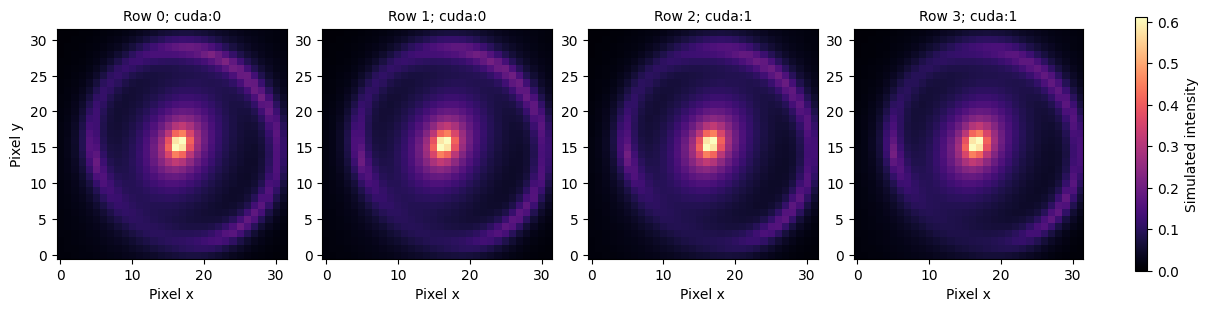

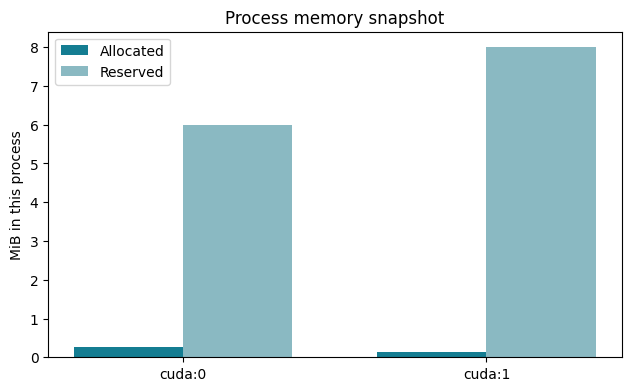

{
  "allocated_MiB": {
    "cuda:0": 0.27197265625,
    "cuda:1": 0.14697265625
  },
  "reserved_MiB": {
    "cuda:0": 6.0,
    "cuda:1": 8.0
  }
}


In [3]:
if READY:
    arrays = images.detach().cpu().numpy()
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), constrained_layout=True)
    for index, ax in enumerate(axes):
        im = ax.imshow(arrays[index], origin="lower", cmap="magma", vmin=0, vmax=arrays.max())
        ax.set_title(f"Row {index}; {homes[index // 2]}", fontsize=10)
        ax.set_xlabel("Pixel x")
        if index == 0:
            ax.set_ylabel("Pixel y")
    fig.colorbar(im, ax=axes, label="Simulated intensity", shrink=0.8)
    plt.show()

    allocated = [torch.cuda.memory_allocated(home) / 2**20 for home in homes]
    reserved = [torch.cuda.memory_reserved(home) / 2**20 for home in homes]
    fig, ax = plt.subplots(figsize=(6.2, 3.8), constrained_layout=True)
    positions = np.arange(2)
    ax.bar(positions - 0.18, allocated, 0.36, label="Allocated", color="#147d92")
    ax.bar(positions + 0.18, reserved, 0.36, label="Reserved", color="#8ab9c2")
    ax.set_xticks(positions, homes)
    ax.set_ylabel("MiB in this process")
    ax.set_title("Process memory snapshot")
    ax.legend()
    plt.show()
    print(
        json.dumps(
            {
                "allocated_MiB": dict(zip(homes, allocated)),
                "reserved_MiB": dict(zip(homes, reserved)),
            },
            indent=2,
        )
    )
    pool.close()

The image captions identify the replica that computed each row, even
though the displayed tensors have been gathered on GPU 0. The memory
bars are a live allocator snapshot for this notebook process, including
the reference, gathered images and prepared replicas. They exclude other
processes and cannot describe total board usage or peak memory. This
notebook makes no timing comparison.

## Submit independent simulators and a dependent task

Each submitted simulator owns disjoint Caskade state. The difference
task consumes two futures and runs on GPU 0 after its inputs are ready.
Input routing and dependency events are part of the executor contract.

```{mermaid}
flowchart TD
    A[First simulator; cuda:0] --> D[Difference; cuda:0]
    B[Second simulator; cuda:1] --> D
```

The arrows show dependencies. Measure kernel overlap with a profiler.


{
  "first_device": "cuda:0",
  "second_device": "cuda:1",
  "difference_device": "cuda:0",
  "mean_squared_difference": 0.00018471061037681825
}


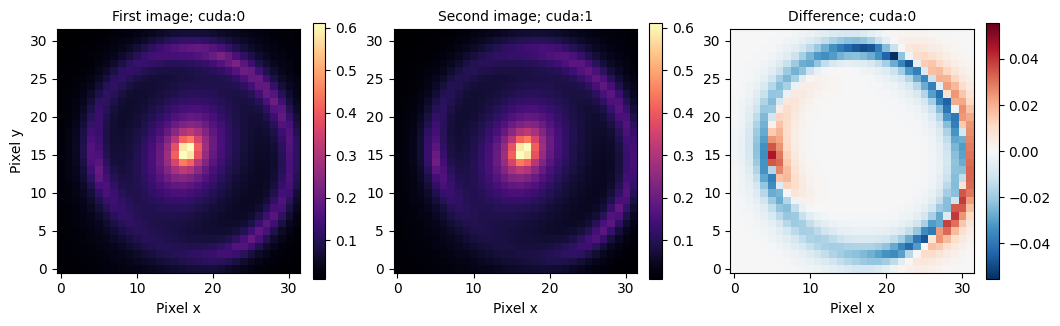

In [4]:
if READY:
    task_models = [image_problem(32, device=home).model for home in homes]
    with ng.AsyncGraphExecutor() as executor:
        first = executor.submit(task_models[0], batch[0], device=homes[0])
        second = executor.submit(task_models[1], batch[3], device=homes[1])
        difference = executor.submit(lambda a, b: b - a, first, second, device=homes[0])
        first_image = first.result()
        second_image = second.result()
        delta = difference.result()
    assert str(first_image.device) == homes[0]
    assert str(second_image.device) == homes[1]
    assert str(delta.device) == homes[0]
    torch.testing.assert_close(first_image, reference[0], rtol=1e-9, atol=1e-10)
    torch.testing.assert_close(second_image.to(homes[0]), reference[3], rtol=1e-9, atol=1e-10)
    torch.testing.assert_close(delta, reference[3] - reference[0], rtol=1e-9, atol=1e-10)
    print(
        json.dumps(
            {
                "first_device": str(first_image.device),
                "second_device": str(second_image.device),
                "difference_device": str(delta.device),
                "mean_squared_difference": float(delta.square().mean()),
            },
            indent=2,
        )
    )

    fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4), constrained_layout=True)
    for ax, image, title in zip(
        axes[:2], (first_image, second_image), ("First image; cuda:0", "Second image; cuda:1")
    ):
        im = ax.imshow(image.detach().cpu(), origin="lower", cmap="magma")
        ax.set_title(title, fontsize=10)
        fig.colorbar(im, ax=ax, shrink=0.8)
    limit = float(delta.abs().max())
    im = axes[2].imshow(
        delta.detach().cpu(), origin="lower", cmap="RdBu_r", vmin=-limit, vmax=limit
    )
    axes[2].set_title("Difference; cuda:0", fontsize=10)
    fig.colorbar(im, ax=axes[2], shrink=0.8)
    for ax in axes:
        ax.set_xlabel("Pixel x")
    axes[0].set_ylabel("Pixel y")
    plt.show()

## Ownership and execution limits

Each replica pool and prepared program supports one caller at a time.
Use separate pools for simultaneous host callers. Reusing one mutable model across
replicas or simultaneous tasks violates Caskade's parameter-context
ownership. Every task must return tensors on its declared home.

The executor carries the caller's grad, inference and autocast modes
into its worker. Copies preserve ordinary autograd relationships. CPU
access waits for the needed data. A compiled one-GPU batch can still be
faster than a small replica batch; capture and gathering have costs.

This release runs in one process. Data-parallel optimizer synchronization,
process-per-device execution and multi-host execution remain outside its
scope. Use a CUDA profile to investigate overlap.
